In [ ]:
import pandas as pd
from os.path import join as pjoin
import numpy as np
import matplotlib.pyplot as plt
import pickle
import matplotlib
import cortex
import pickle
from plotting import *

rootdir =  "/YOUR_PATH/principlesOTC"

color_map = {
    "animacy": "#fc03c2",
    "curvature": "#7a2120",
    "natural": "#a8a39f",
    "heavy": "#ff8400",
    "size": "#00b5e0",
    "moves": "#6602bf",
    "precious": "#0a0a0a",
    "be_moved": "#cd90de",
    "pleasant": "#c04e00",
    "arousal": "#00cc39",
    "agency": "#f5d742",
    "humanness": "#317030",
    "cuteness": "#ffb88c",
    "hardness": "#3a5d78",
    "manipulability": "#0036cc",
}

properties = list(color_map.keys())

roi_select = ['V1', 'V2', 'V3', 'FFA','OFA', 'PPA', 'EBA', 'pSTS', 'MPA', 'OPA']
xfm = 'align_auto'

# Figure 2

In [ ]:
import os
from os.path import join as pjoin
import pandas as pd
import matplotlib 
import nibabel as nib

rootdir = "/Users/laurastoinski/playground/anisize"

datadir = pjoin(rootdir, "results/Fig2_Fig5_property_encoding")
resdir = pjoin(datadir, "Fig2")
os.makedirs(resdir, exist_ok=True)

vlims = 0.003

regressors = ["animacy", "size"] 
colormaps = [
    ['#e5ffd1', '#a3ff5c','#474747', '#000000', '#590f4a','#ff00b3', '#fad1ff'],
    ['#fff9d1','#ffe100', '#59500f', '#000000','#0f4959', '#008cff', '#d1fdff']]

    
    
for reg, col in zip(regressors, colormaps):
    cm =  matplotlib.colors.LinearSegmentedColormap.from_list("mymap", col, N=200, gamma=1.0)

    for sub in ['1', '2', '3']:
        filename = pjoin(datadir, f"sub0{sub}_regression_coefficients_whole_brain_{reg}")
        img = nib.load(f"{filename}.nii.gz")
        
        outname = pjoin(resdir,  f"{filename}.png")
        plot_flatmap(sub, img, cm, vlims, outname)

# Figure 3b

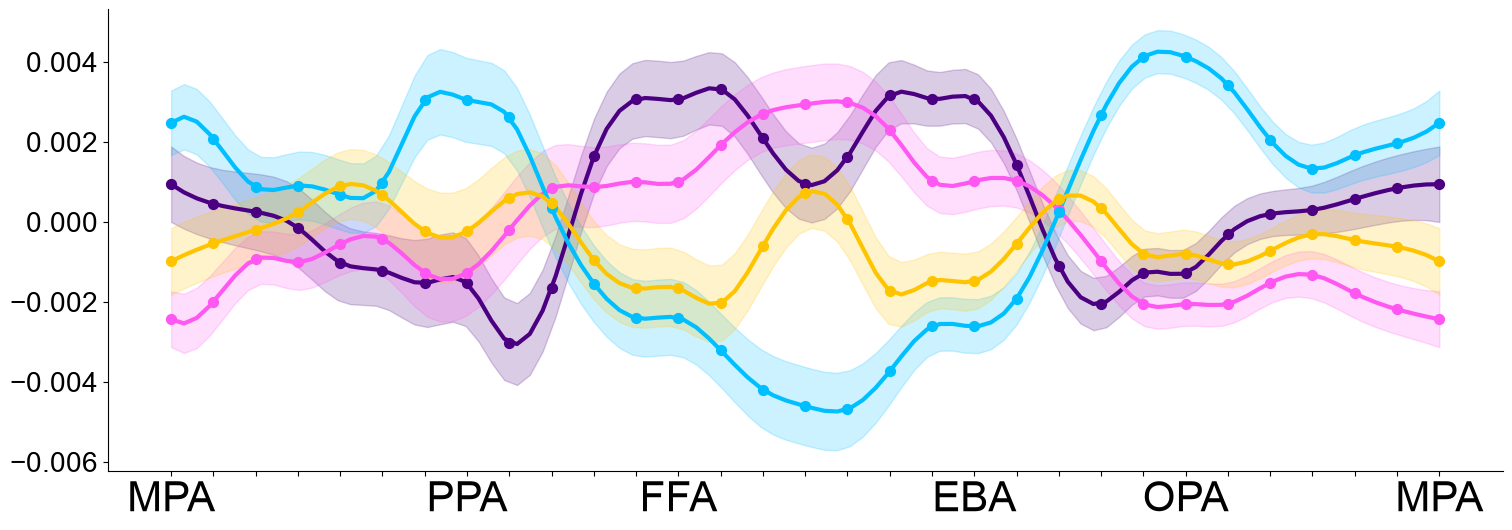

In [4]:
resdir =  pjoin(rootdir, "results/Fig3_tripartite")
grandMean = pd.read_csv(pjoin(resdir, f"Avg_means_surf_sphere_tripartite.csv"))
outname = f"Avg_animals_vs_objects_response_profile_size.png"

# SEM of sphere-voxel (True) vs. SEM of ttest mean (False)
plot_tripartite(resdir, grandMean, outname, plot_original=True, plot_confi = True)

# Figure 4

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
from os.path import join as pjoin
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import squareform


eventdir = pjoin(rootdir, "data")
resdir = pjoin(rootdir, "results/Fig4_correlations_MDS")
os.makedirs(resdir, exist_ok=True)

# Load and preprocess data
events = pd.read_csv(pjoin(eventdir, "720_events.csv"))
events["curvature"] = 100 - events["curvature"] # reverse to "0 = rectilienar" and "100 = very curvy" to make more interpreable


# Standardize data
df = events[properties]
scaler = StandardScaler()
df_stand = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

# ---------------------------------------------------------------------
# Correlation matrix
# ---------------------------------------------------------------------

# Compute full-precision Pearson correlation matrix
correlation_matrix = df_stand.corr(method="pearson")

# Save raw/full-precision correlation matrix
correlation_csv_path = pjoin(resdir, "correlation_matrix.csv")
correlation_matrix.to_csv(correlation_csv_path)
print(f"Correlation matrix saved to {correlation_csv_path}")

# ---------------------------------------------------------------------
# Hierarchical clustering
# ---------------------------------------------------------------------

# Convert correlations to distances
distance_matrix = 1 - correlation_matrix

# Set diagonal exactly to zero to avoid numerical issues
np.fill_diagonal(distance_matrix.values, 0)

# Convert square distance matrix to condensed form
condensed_distance = squareform(distance_matrix.values, checks=True)

# Perform hierarchical clustering using average linkage
linkage_matrix = sch.linkage(condensed_distance, method="average")

# Save raw linkage matrix
linkage_df = pd.DataFrame(
    linkage_matrix,
    columns=["cluster_1", "cluster_2", "distance", "n_observations"]
)

linkage_csv_path = pjoin(resdir, "hierarchical_clustering.csv")
linkage_df.to_csv(linkage_csv_path, index=False)
print(f"Hierarchical clustering saved to {linkage_csv_path}")

# ---------------------------------------------------------------------
# Extract dendrogram order
# ---------------------------------------------------------------------

dendro_data = sch.dendrogram(
    linkage_matrix,
    labels=correlation_matrix.columns.tolist(),
    no_plot=True
)

dendrogram_order = dendro_data["ivl"]

# Reorder the correlation matrix according to dendrogram order
reordered_corr_matrix = correlation_matrix.loc[
    dendrogram_order,
    dendrogram_order
]

# Round only for visualization
reordered_corr_matrix_plot = reordered_corr_matrix.round(2)

# ---------------------------------------------------------------------
# Plot dendrogram
# ---------------------------------------------------------------------

plt.figure(figsize=(10, 7))

sch.dendrogram(
    linkage_matrix,
    labels=correlation_matrix.columns.tolist(),
    leaf_rotation=90,
    leaf_font_size=30,
    color_threshold=0,
    link_color_func=lambda k: "black"
)

ax = plt.gca()

# Update leaf-label font size and color
xlbls = ax.get_xmajorticklabels()

for lbl in xlbls:
    lbl.set_fontsize(20)
    prop = lbl.get_text()

    if prop in color_map:
        lbl.set_color(color_map[prop])

# Remove y-axis and spines
ax.yaxis.set_visible(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(False)


dendro_path = pjoin(resdir, "hierarchical_dendrogram.png")

plt.tight_layout()
plt.savefig(dendro_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Dendrogram saved to {dendro_path}")

# ---------------------------------------------------------------------
# Plot reordered correlation heatmap
# ---------------------------------------------------------------------

cmap = sns.diverging_palette(250, 10, as_cmap=True)

plt.figure(figsize=(15, 15))

sns.heatmap(
    reordered_corr_matrix_plot,
    fmt=".2f",
    annot=True,
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar=False,
    xticklabels=dendrogram_order,
    yticklabels=dendrogram_order,
    annot_kws={"size": 20}
)

plt.xticks(rotation=45, ha="right", fontsize=30)
plt.yticks(rotation=0, fontsize=30)

# Save heatmap
heatmap_path = pjoin(resdir, "correlation_matrix_heatmap.png")

plt.savefig(heatmap_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"Heatmap saved to {heatmap_path}")

Correlation matrix saved to /Users/laurastoinski/playground/anisize/results/Fig4_correlations_MDS/correlation_matrix.csv


ValueError: underlying array is read-only

# Figure 5

In [ ]:
# a) Plot regression results
vlims = 0.003

datadir = pjoin(rootdir, "results/Fig2_Fig5_property_encoding")
resdir = pjoin(datadir, "Fig5")
os.makedirs(resdir, exist_ok=True)

# costum color maps
col = [ "#70ddff", "#00c2ff","#000000","#ff4900","#f78b60"]
cm =  matplotlib.colors.LinearSegmentedColormap.from_list("mymap", col, N=200, gamma=1.0)    
    
for reg in properties:
    for sub in ['1', '2', '3']:
        filename = pjoin(datadir, f"sub0{sub}_regression_coefficients_whole_brain_{reg}")
        img = nib.load(f"{filename}.nii.gz")
        
        outname = pjoin(datadir, f"{filename}.png")
        plot_flatmap(sub, img, cm, vlims, outname)

# Figure 6

In [ ]:
datadir =  pjoin(rootdir, "results/Fig5_smoothness_bootstrap")

out_dir = Path(pjoin(datadir, "plots"))
out_dir.mkdir(parents=True, exist_ok=True)

metrics = [ 
    "wtv_sigma_3mm",
    f"wtv_rel_mean_g1.0_sigma_3mm_rel",
]

subjects = ["01", "02", "03"]
include_shuffled = True

subject_to_df = {}
shuf_to_df = {}

# 1) load everything first (so we can compute a single shared regressor ordering)
for sub in subjects:
    data = pd.read_csv(pjoin(
        datadir, 
        f"sub{sub}_property_topographies_smoothness_weightedVar_Dijkstra-r3x3_gamma1.0_rel-mean.csv")
    )

    df_sub = avg_bootstrap(data, sub, metrics, groups=["regressor"], alpha=0.05)

    shuf_mean = pd.Series(dtype=float)
    if include_shuffled:
        shuf_df = pd.read_csv(pjoin(
        datadir, 
        f"sub{sub}_property_topographies_smoothness_weightedVar_shuffled_Dijkstra-r3x3_gamma1.0_rel-mean.csv"
        ))

        # average across bootstraps (and across regressors if there are multiple, though usually only "shuffled")
        shuf_ci = avg_bootstrap(shuf_df, sub, metrics, groups=["regressor"], alpha=0.05)
        shuf_mean = shuf_ci.mean(numeric_only=True)

    subject_to_df[sub] = df_sub.copy()
    shuf_to_df[sub] = shuf_mean.copy()


# Save the numerical values used for the subject-level error bars and
# the corresponding across-subject summaries.
per_subject_csv, across_subjects_csv = save_metric_summaries(
    subject_to_df=subject_to_df,
    metrics=metrics,
    out_dir=out_dir,
    ci_level=0.95,
)

print(f"Saved: {per_subject_csv}")
print(f"Saved: {across_subjects_csv}")

# 2) choose the single metric that defines x ordering for ALL plots
#    this is the knob you asked for: change this one line and everything reorders consistently.
sort_metric = "wtv_sigma_3mm"

regressor_order = get_regressor_order(
    subject_to_df=subject_to_df,
    sort_metric=sort_metric,
    include_shuffled=False,
)

# 3) per-subject plots, all using the same regressor_order
for sub in subjects:
    df_sub = subject_to_df[sub]

    plot_metrics(sub, df_sub, metrics, regressor_order=regressor_order, out_dir=out_dir)
    plot_two_metrics_subjectwise(sub, df_sub, "mean", regressor_order=regressor_order, out_dir=out_dir)

# 4) all-subject plots, also using the same regressor_order
for metric in metrics:
    plot_metric_all_subjects(
        subject_to_df=subject_to_df,
        shuf_to_df=shuf_to_df,
        metric=metric,
        regressor_order=regressor_order,
        ci_level=0.95,
        out_dir=out_dir,
    )

Saved: /Users/laurastoinski/playground/anisize/results/Fig5_smoothness_bootstrap/plots/smoothness_per_subject_regressor.csv
Saved: /Users/laurastoinski/playground/anisize/results/Fig5_smoothness_bootstrap/plots/smoothness_across_subjects_regressor.csv
Saved: /Users/laurastoinski/playground/anisize/results/Fig5_smoothness_bootstrap/plots/All_subjects_wtv_sigma_3mm.csv
Saved: /Users/laurastoinski/playground/anisize/results/Fig5_smoothness_bootstrap/plots/All_subjects_wtv_rel_mean_g1.0_sigma_3mm_rel.csv


# Figure 7a

Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag


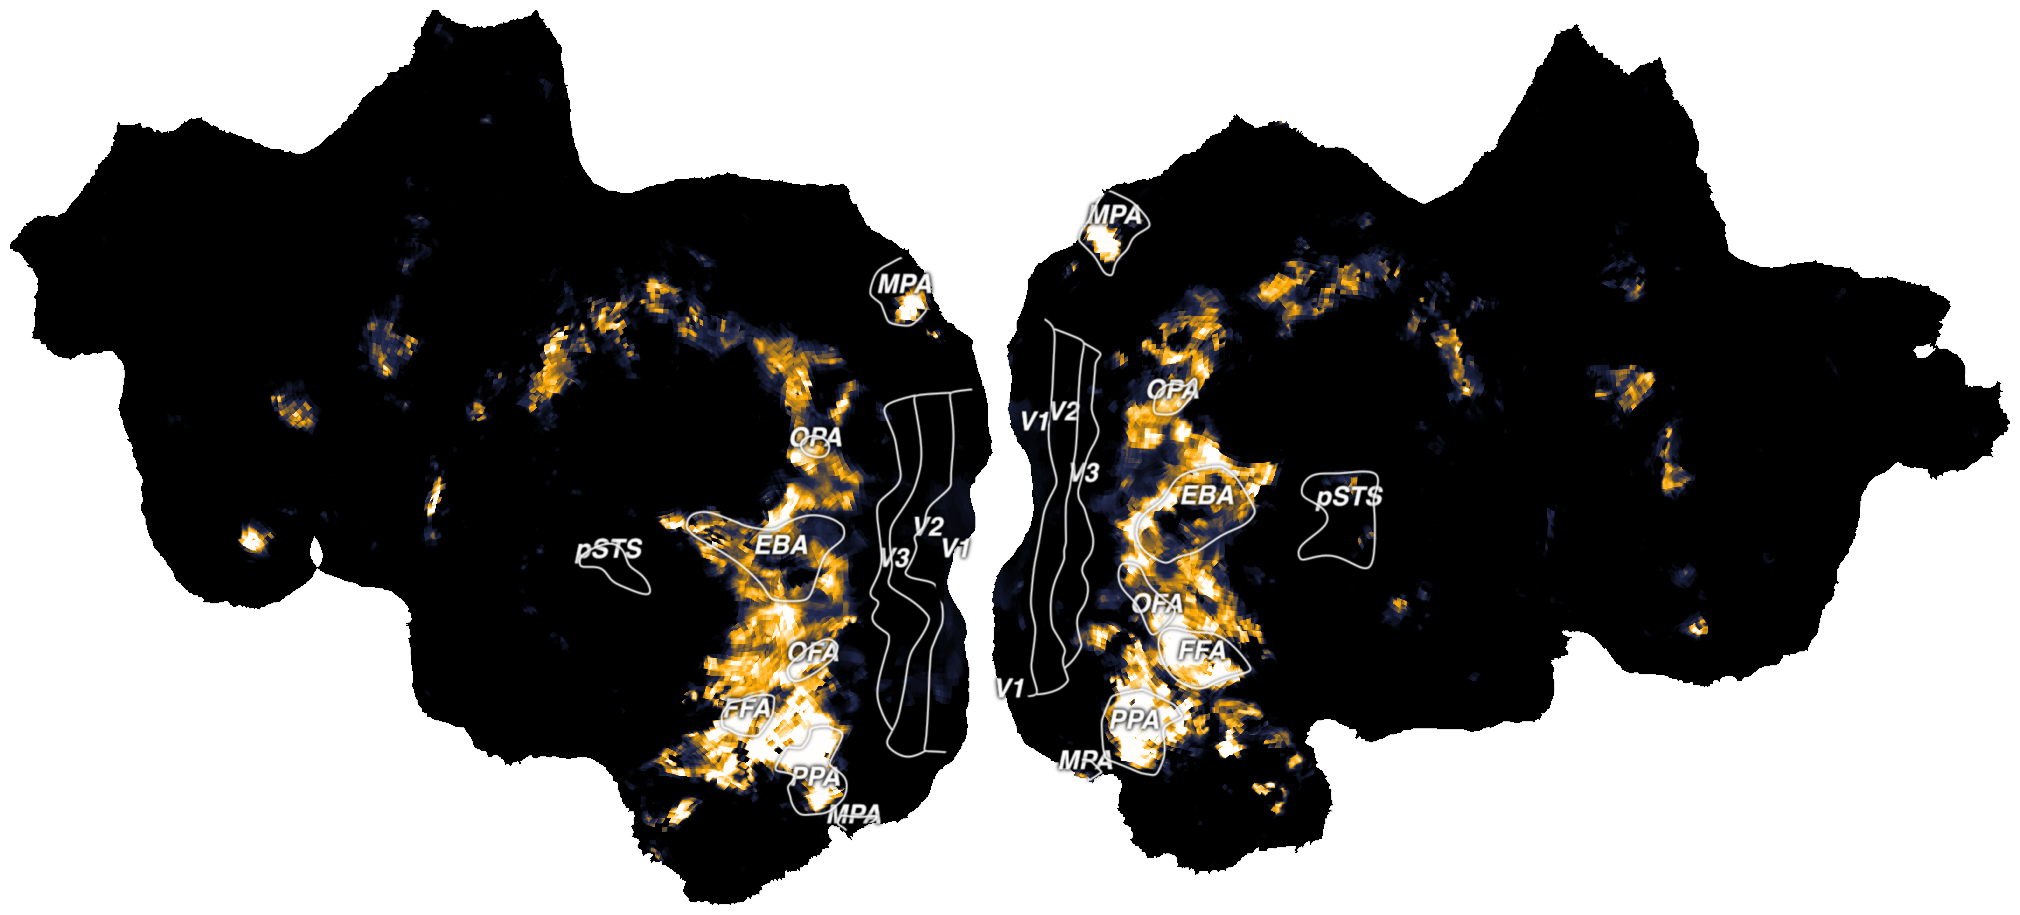

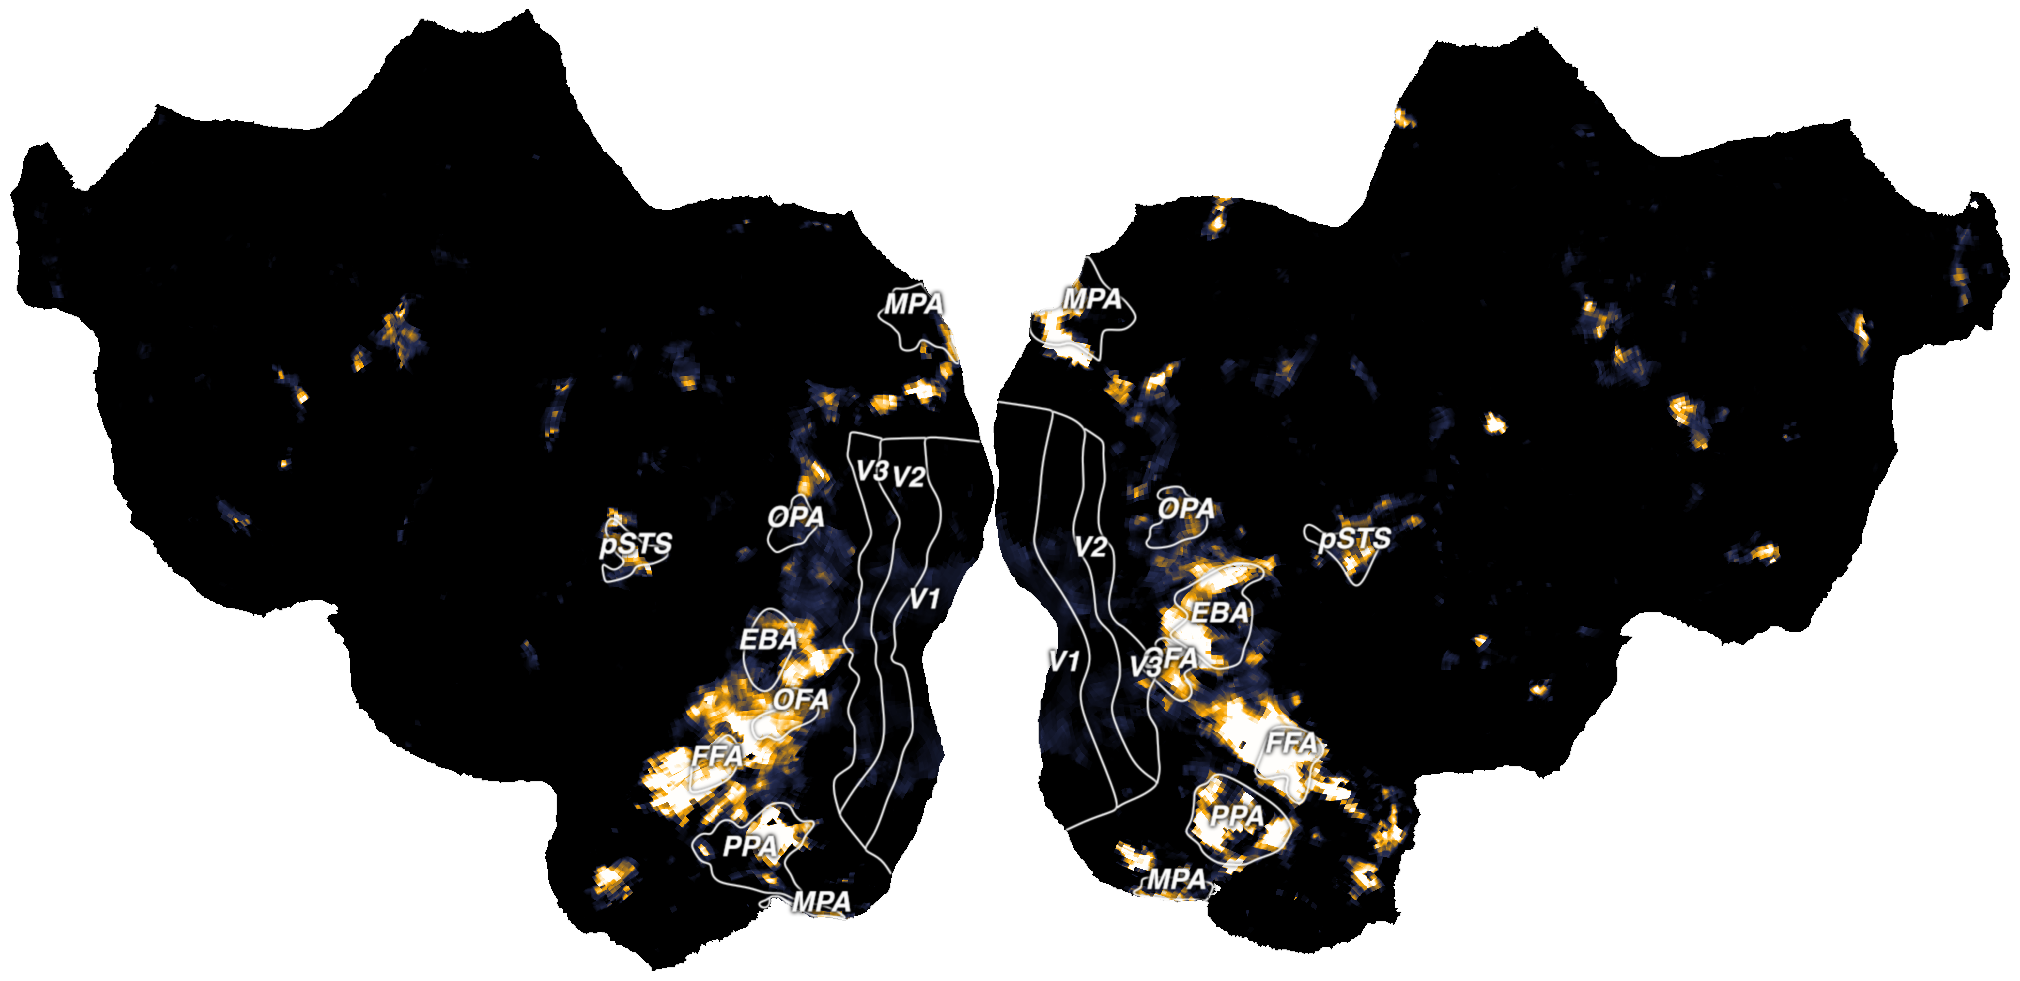

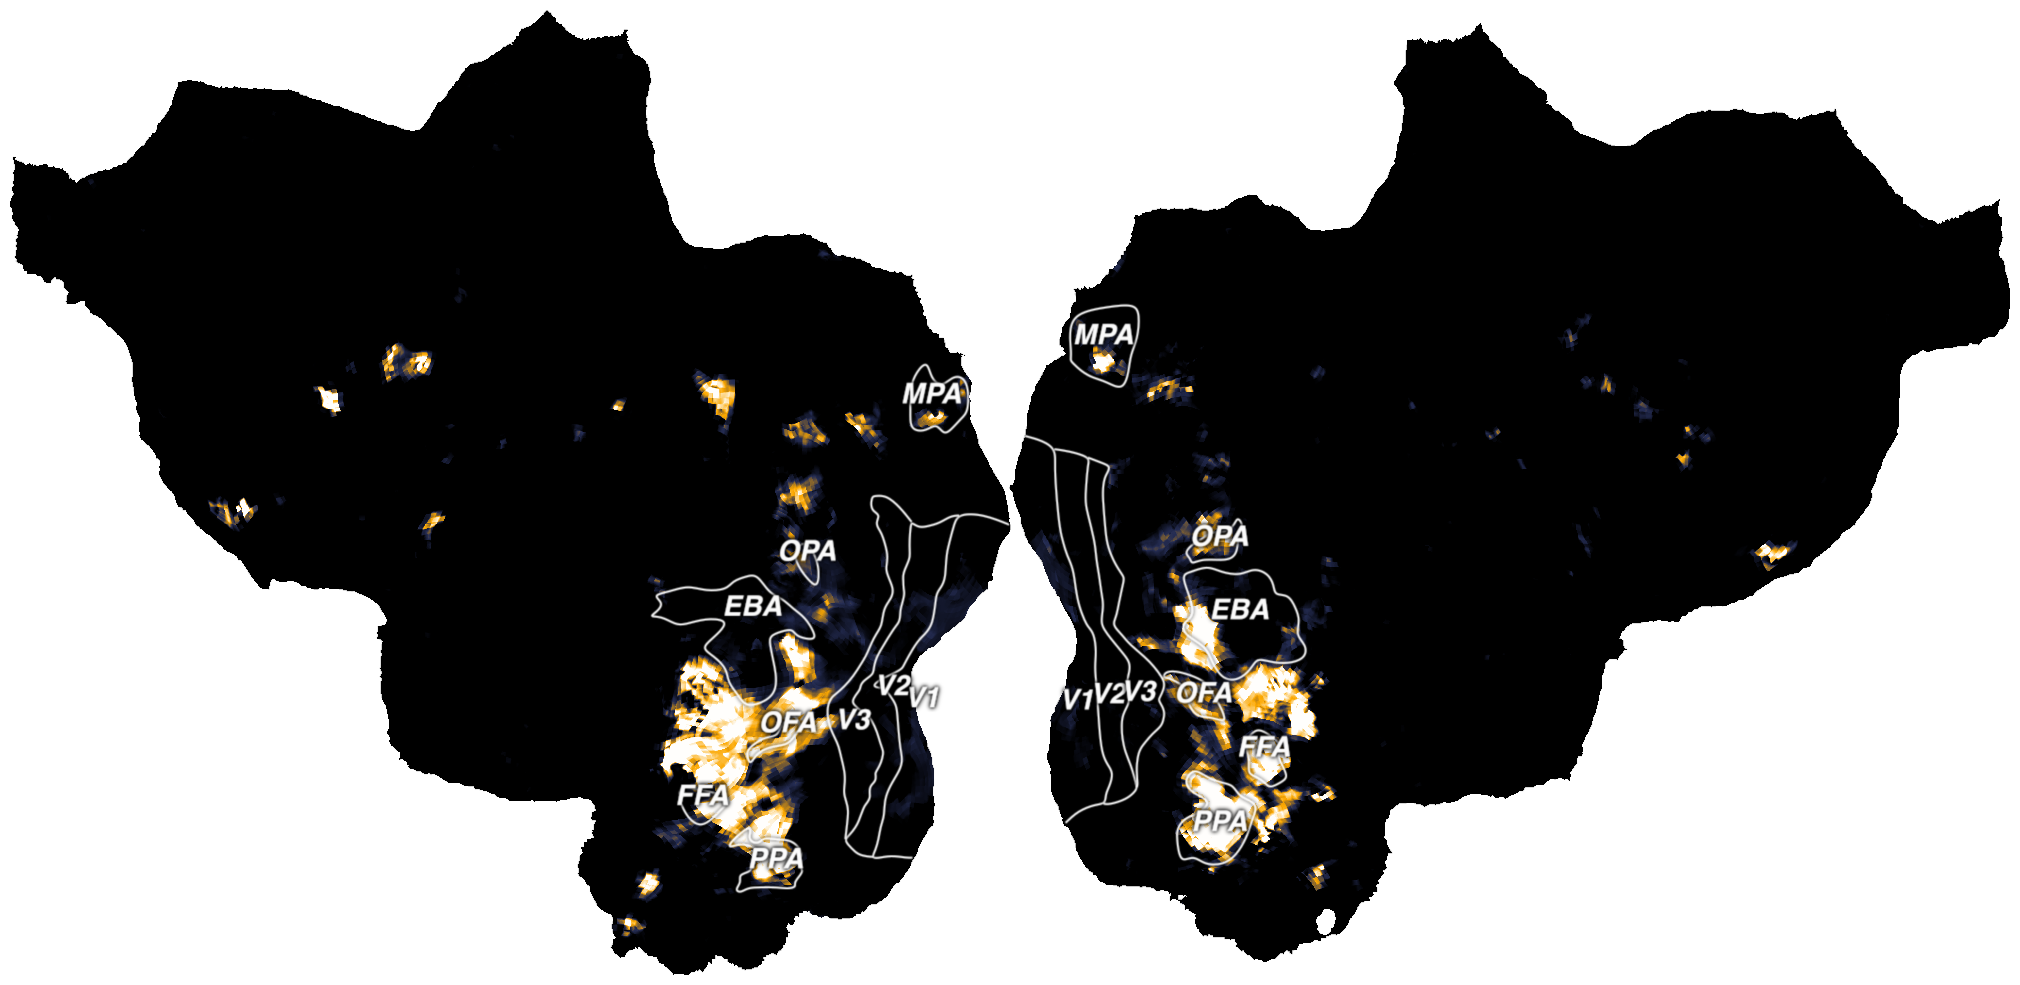

In [15]:
######################
#version = ""
version = "_noiseNormed"

datadir = pjoin(rootdir, "results/Fig7c_hierarchical_partition/train80")
#########################

model_info = pd.read_csv(pjoin(datadir, "hierarchical_partition_models.csv")) 
maxmodel = model_info["index"].max() # full model with all regressors 


col = ['#000000', '#252d54',  "#fca800", "#fffefc"]
cm = matplotlib.colors.LinearSegmentedColormap.from_list("mymap", col, N=200, gamma=1.0)

for sub in ['1', '2', '3']:
    filename = pjoin(datadir, f"sub0{sub}_cross_vali_r_squared_model{maxmodel}_totalVar{version}")
    image = nib.load(f"{filename}.nii.gz")
    outname = f"{filename}.png"
    vlim = [0, 1]
    if version == "":
        vlim = [0, 0.2]
    
    plot_flatmap(sub, image, cm, vlim, outname, legend = False)

# Figure 7b

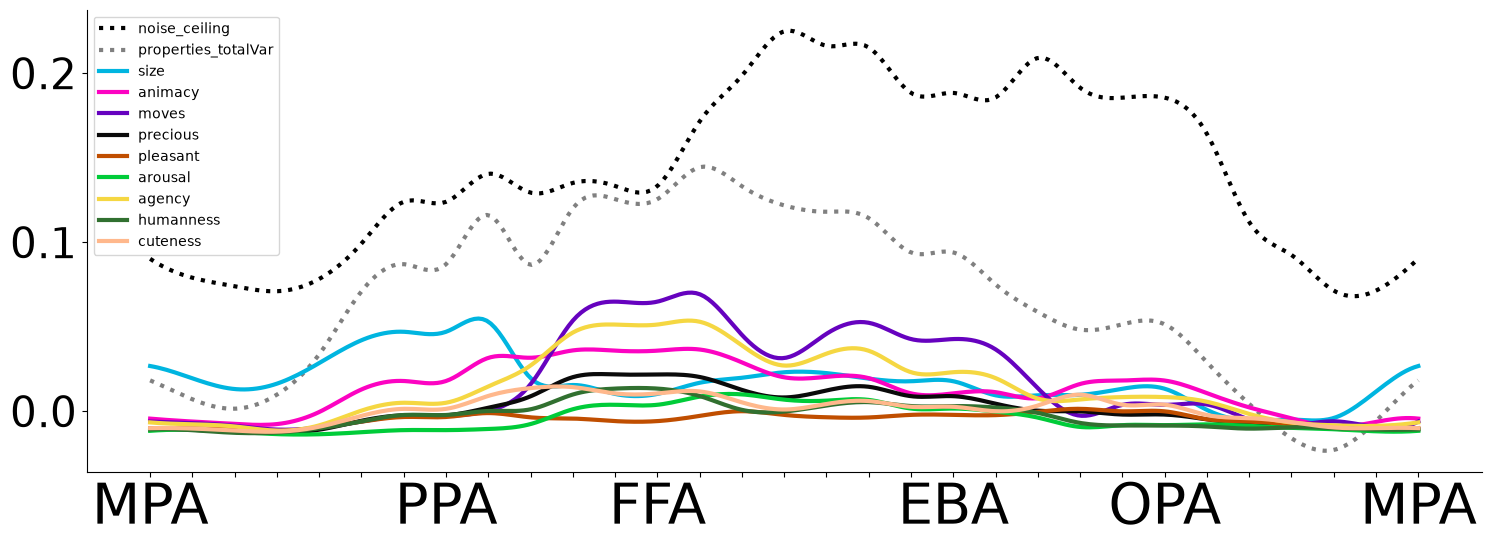

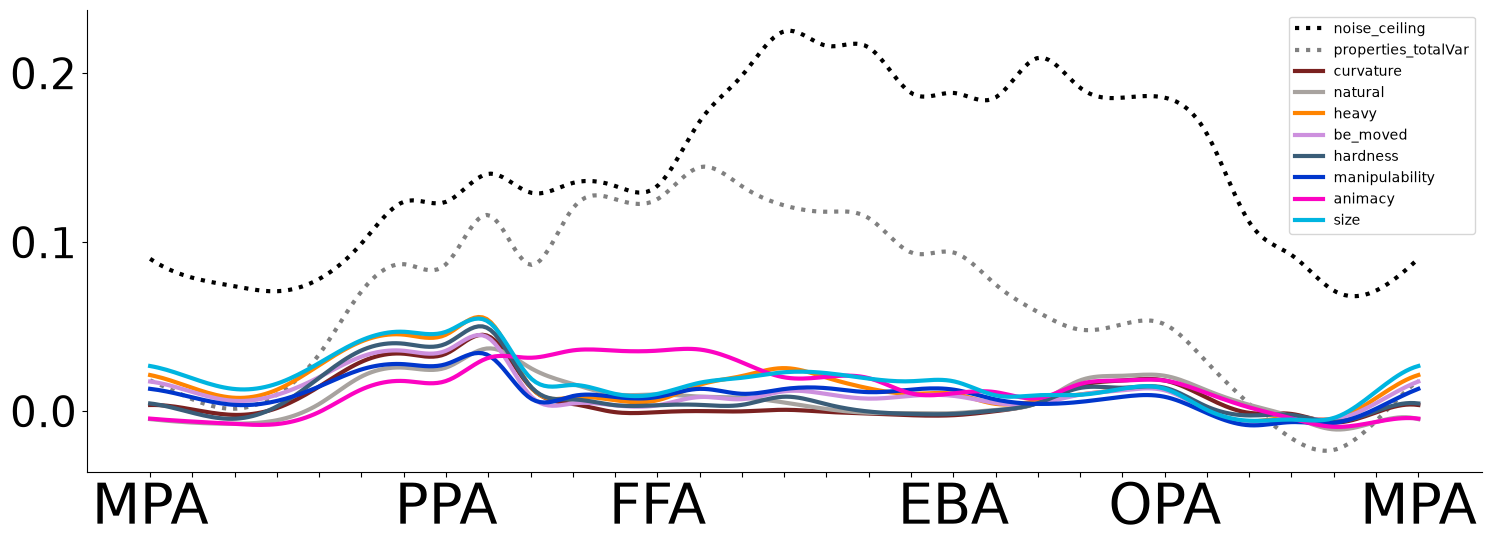

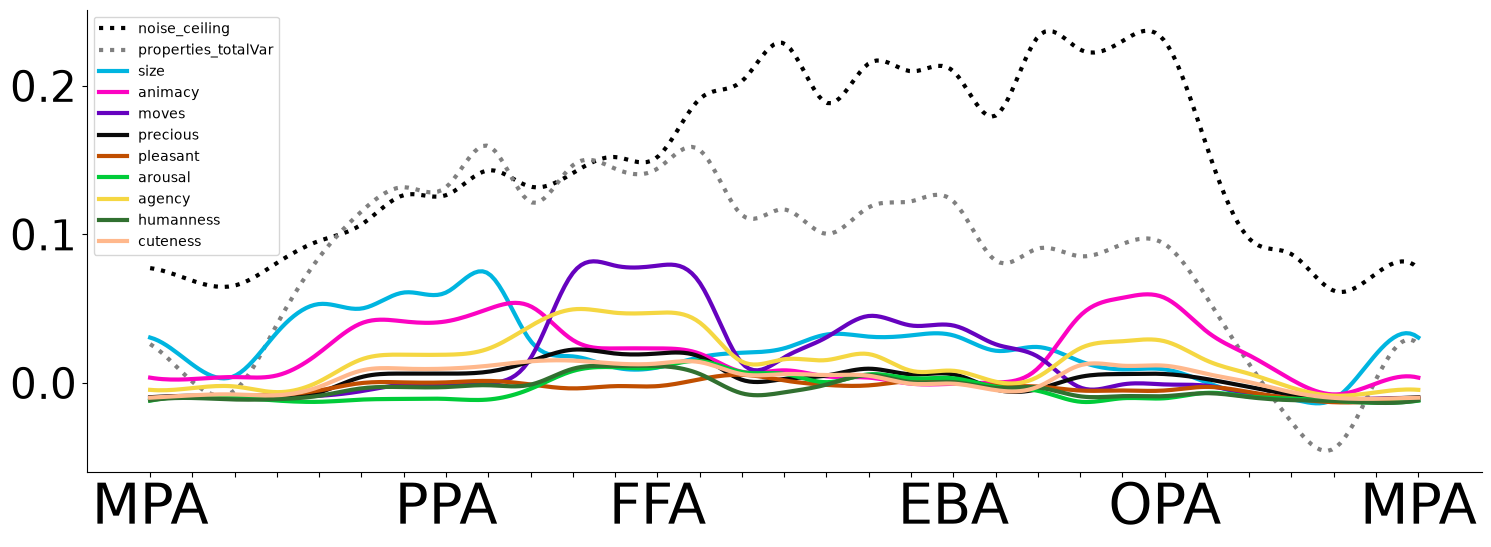

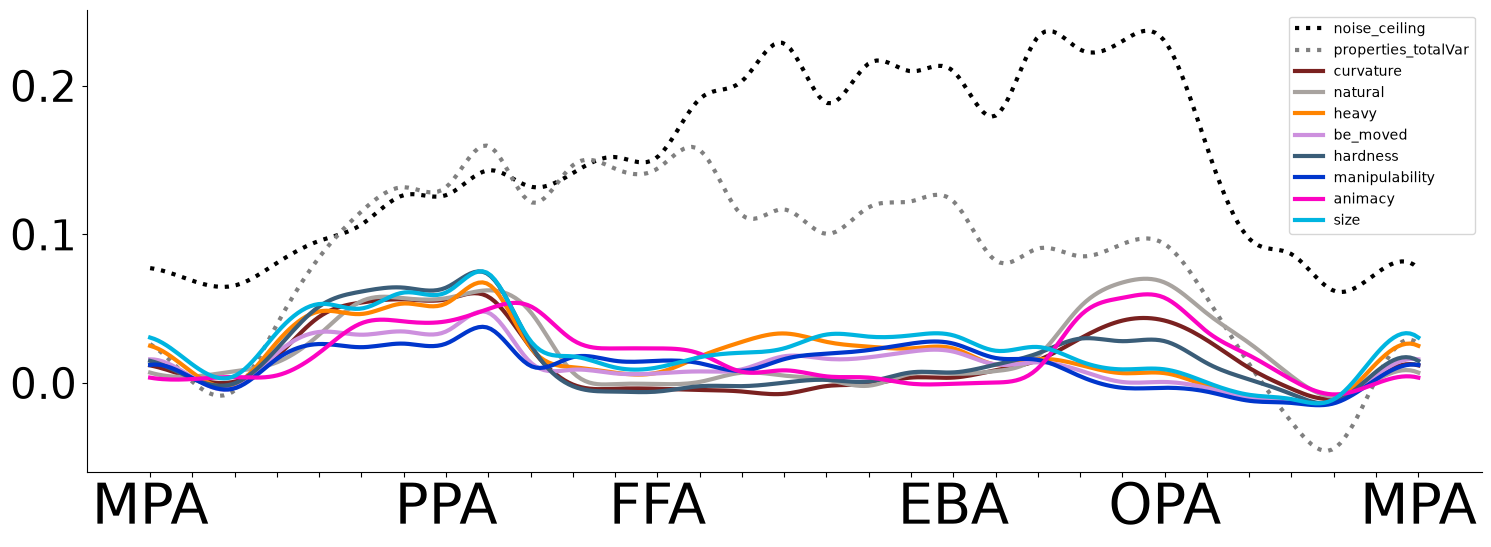

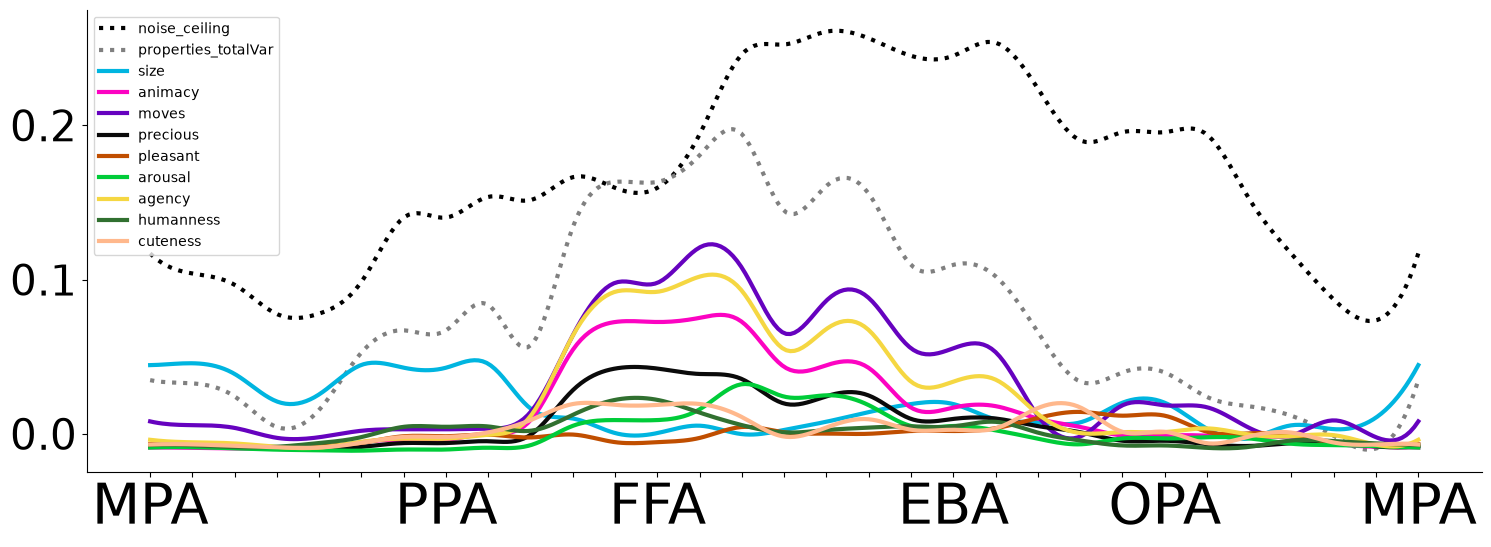

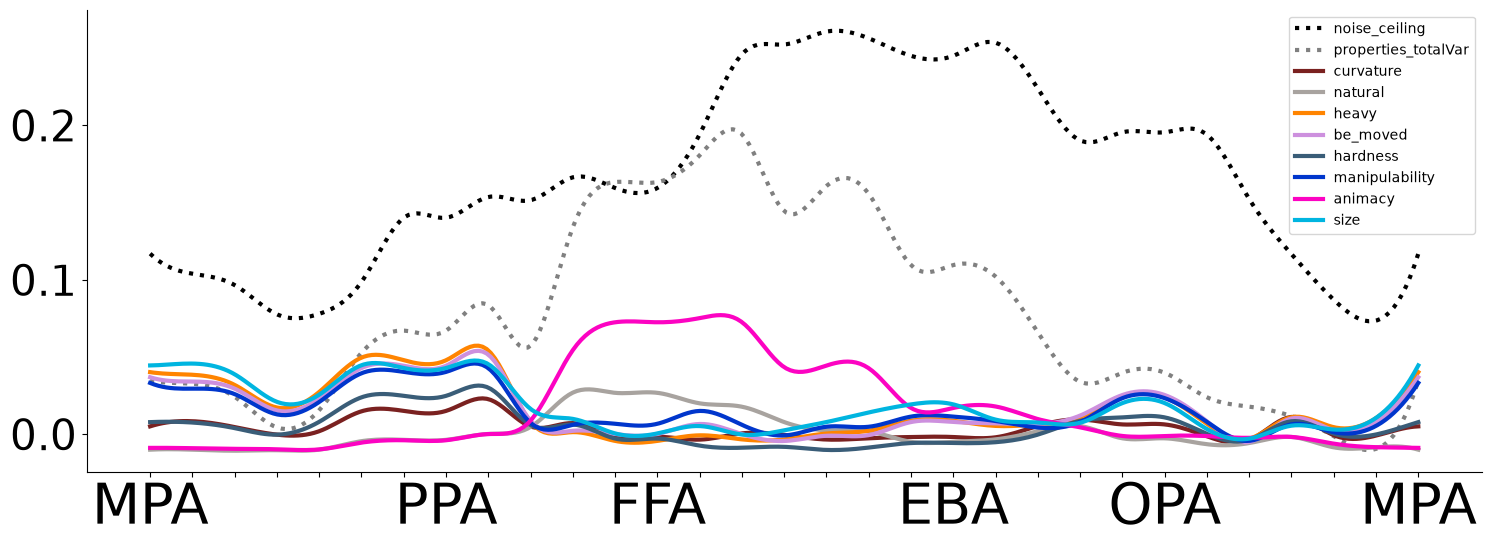

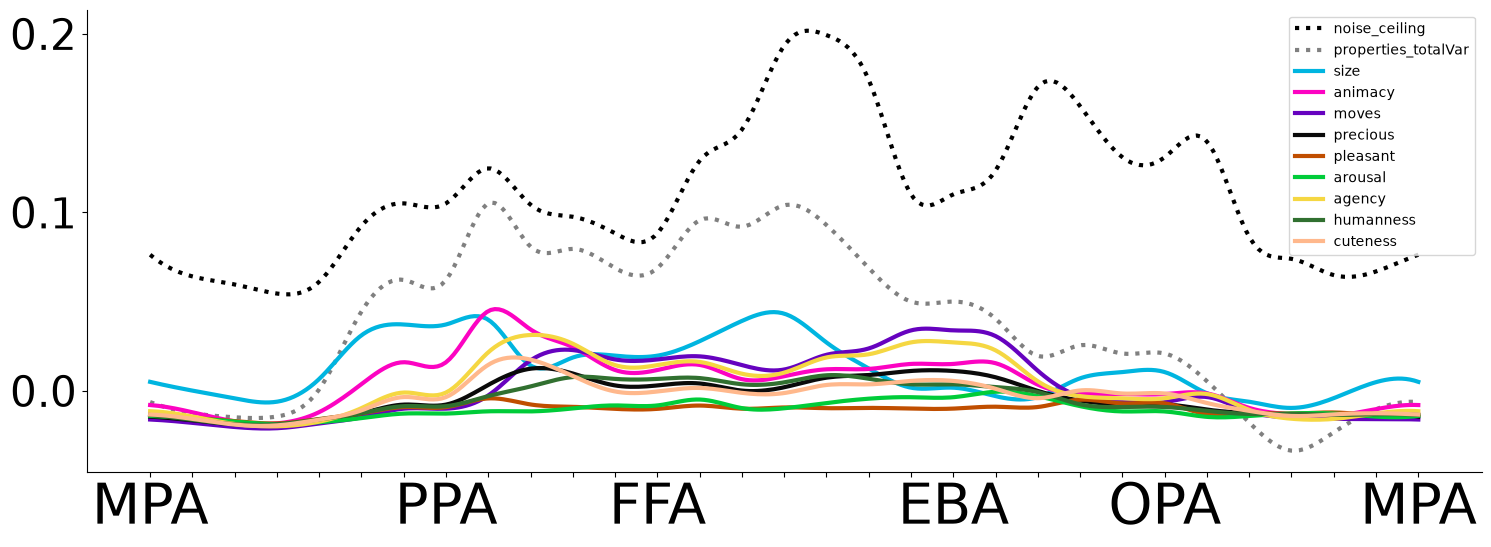

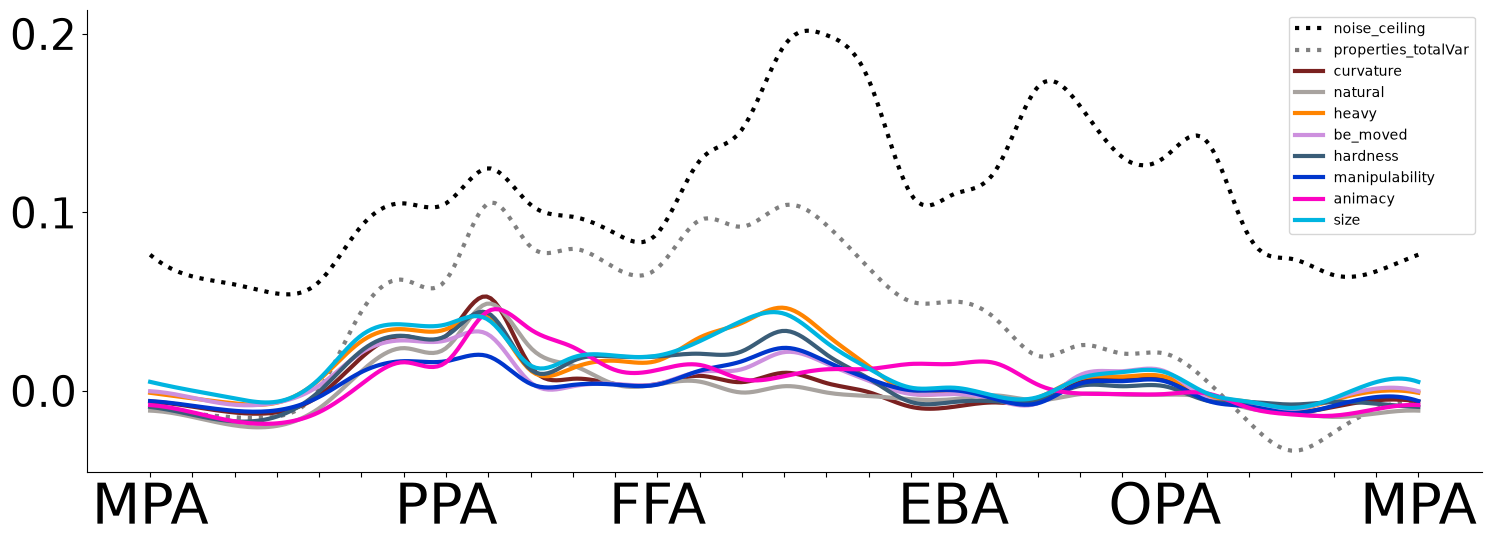

In [ ]:
from utils import activity_per_roi

datadir = pjoin(rootdir, "results/Fig7b_univariate_r2")

labels = ["noise_ceiling", "properties_totalVar"] + list(properties)
  
# extract vector of roi  ---------------------------------------------------------------------------------

all_df = []
for subject in [1, 2, 3]:
    paths = [pjoin(rootdir, f"data/noise_ceilings/sub-0{subject}_nc_n-12.nii.gz"),
            pjoin(rootdir, f"results/Fig7c_hierarchical_partition/train80/sub0{subject}_cross_vali_r_squared_model32766_totalVar.nii.gz")]
    for prop in properties:
        cur_path = pjoin(datadir, f"sub0{subject}_rsquared_whole_brain_{prop}_crossvali.nii.gz")
        paths.append(cur_path)

    df = activity_per_roi(subject, paths, labels, rootdir)
    all_df.append(df)


df_all = pd.concat(all_df)

df_all["noise_ceiling"] = df_all["noise_ceiling"] / 100
df_all.to_csv(pjoin(datadir, "weights_per_surf_sphere_univariate_property_rsquared_crossvali.csv"), index=False)

grandMean = df_all.groupby(['sphere'], as_index=False).mean()
grandMean.to_csv(pjoin(datadir, "Avg_weights_per_surf_sphere_univariate_property_rsquared_crossvali.csv"), index=False)


# Plot ---------------------------------------------------------------------------------
set1 = ['size', 'animacy', 'moves', 'precious', 'pleasant',
        'arousal', 'agency', 'humanness', 'cuteness']
set2 = [s for s in properties if s not in set1] + ['animacy', 'size']


set1 = ["noise_ceiling", "properties_totalVar"] + set1
set2 = ["noise_ceiling", "properties_totalVar"] + set2
color_map['noise_ceiling'] = 'black'
color_map['properties_totalVar'] = 'gray'

    

anchors = [7, 5, 7, 5, 7]
others = [' ']
sphere_labels = ['MPA'] + others * (anchors[0] - 1) + ['PPA'] + others * (anchors[1] - 1) + ['FFA'] + others * (anchors[2] - 1) + ['EBA'] + others * (anchors[3] - 1) + ['OPA'] + others * (anchors[4] - 2) + ["MPA"] 


for s, setv in enumerate([set1, set2]):
  plotname = f'set{s+1}'
  fig, ax = plt.subplots(figsize=(18, 6))
  ax.set_facecolor('white') 
  for reg in setv:

    linestyle = ':'
    if reg not in ["noise_ceiling", "properties_totalVar"]:
        linestyle = '-'
        
    x = np.linspace(0, len(grandMean)-1, num=len(grandMean)*10) # interpolat
    y = grandMean[reg] 

    plt.plot(x, interp1d(np.arange(len(grandMean)), y, kind='cubic')(x), label=reg, c=color_map[reg], lw=3, linestyle=linestyle)
    plt.legend(fontsize=10)
        
    ax.set_xticks(np.arange(0, len(grandMean), 1))
    ax.set_xticklabels(sphere_labels, fontsize=40)  
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.tick_params(axis='y', labelsize=30) 

  plt.savefig(pjoin(datadir, f"response_profile_univariate_property_rsquared_crossvali_{plotname}.png"), dpi=600)
  plt.show()
  
  
for sub in [1, 2, 3]:
  df = df_all[df_all['subject'] == sub]

  for s, setv in enumerate([set1, set2]):
    plotname = f'set{s+1}'
    fig, ax = plt.subplots(figsize=(18, 6))
    ax.set_facecolor('white') 
    for reg in setv:

      linestyle = ':'
      if reg not in ["noise_ceiling", "properties_totalVar"]:
          linestyle = '-'
          
      x = np.linspace(0, len(df)-1, num=len(df)*10) # interpolat
      y = df[reg] 

      plt.plot(x, interp1d(np.arange(len(df)), y, kind='cubic')(x), label=reg, c=color_map[reg], lw=3, linestyle=linestyle)
      plt.legend(fontsize=10)
          
      ax.set_xticks(np.arange(0, len(df), 1))
      ax.set_xticklabels(sphere_labels, fontsize=40)  
      ax.spines['right'].set_visible(False)
      ax.spines['top'].set_visible(False)
      ax.tick_params(axis='y', labelsize=30) 
  

    plt.savefig(pjoin(datadir, f"response_profile_univariate_property_rsquared_crossvali_{plotname}_S{sub}.png"), dpi=600)
    plt.show()

# Figure 7c

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from os.path import join as pjoin
from scipy.interpolate import interp1d

######################
#version = ""
version = "_noiseNormed"

datadir = pjoin(rootdir, "results/Fig7c_hierarchical_partition/train80")
#########################



df = pd.read_csv(pjoin(datadir, f"Avg_weights_per_surf_sphere_hierarchical_partition{version}.csv"))

y_max = 0.25
anchors = [7, 5, 7, 5, 7]
others = [' ']
sphere_labels =  ['MPA'] + others * (anchors[0] - 1) + ['PPA'] +  others * (anchors[1] - 1)+ ['FFA'] +  others * (anchors[2] - 1)+ ['EBA'] +  others * (anchors[3] - 1)+ ['OPA'] +  others * (anchors[4] - 2) + ["MPA"] 


# I divided the properties into two plots, to make the plot less crowded. But put ani-size in both
set1 = ['size', 'animacy', 'moves', 'precious',   'pleasant',
            'arousal',  'humanness', 'cuteness', 'agency']
set2 = [s for s in properties if s not in set1] + ['animacy', 'size']

for s, setv in enumerate([set1, set2]):
  plotname = f'set{s+1}'
  _, ax = plt.subplots(figsize=(18, 6))
  ax.set_facecolor('white') 
  
  for reg in setv:

      x = np.linspace(0, len(df)-1, num=len(df)*10) # interpolat
      y = df[reg] 

      plt.plot(x, interp1d(np.arange(len(df)), y, kind='cubic')(x), label=reg, c=color_map[reg], lw=3)
      plt.legend(fontsize=10)
          
      ax.set_ylim(0, y_max)
      ax.set_yticks(np.arange(-0.05, y_max, 0.05))
      ax.set_xticks(np.arange(0, len(df), 1))
      ax.set_xticklabels(sphere_labels, fontsize=40)  
      ax.spines['right'].set_visible(False)
      ax.spines['top'].set_visible(False)
      ax.tick_params(axis='y', labelsize=30) 
      

  plt.savefig(pjoin(datadir, f"response_profile_THINGSplus_variancePartition_{plotname}{version}.png"), dpi=600)
  plt.show()
  
  
# also save the participant-wise plots
df_all = pd.read_csv(pjoin(datadir, f"weights_per_surf_sphere_hierarchical_partition{version}.csv"))
   
for sub in [1, 2, 3]:
  df = df_all[df_all['subject'] == sub]

  for s, setv in enumerate([set1, set2]):
    plotname = f'set{s+1}'
    _, ax = plt.subplots(figsize=(18, 6))
    ax.set_facecolor('white') 
    
    for reg in setv:

        x = np.linspace(0, len(df)-1, num=len(df)*10) # interpolat
        y = df[reg] 

        plt.plot(x, interp1d(np.arange(len(df)), y, kind='cubic')(x), label=reg, c=color_map[reg], lw=3)
        #plt.legend(fontsize=10), 
            
        ax.set_ylim(0, y_max)
        ax.set_yticks(np.arange(-0.05, y_max, 0.05))
        ax.set_xticks(np.arange(0, len(df), 1))
        ax.set_xticklabels(sphere_labels, fontsize=40)  
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)
        ax.tick_params(axis='y', labelsize=30) 

    plt.savefig(pjoin(datadir, f"response_profile_THINGSplus_variancePartition_{plotname}{version}_S{sub}.png"), dpi=600)
    plt.close()

# Plot vector-of-rois path

Subject 1: 31 spheres, 278118 vertices
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag


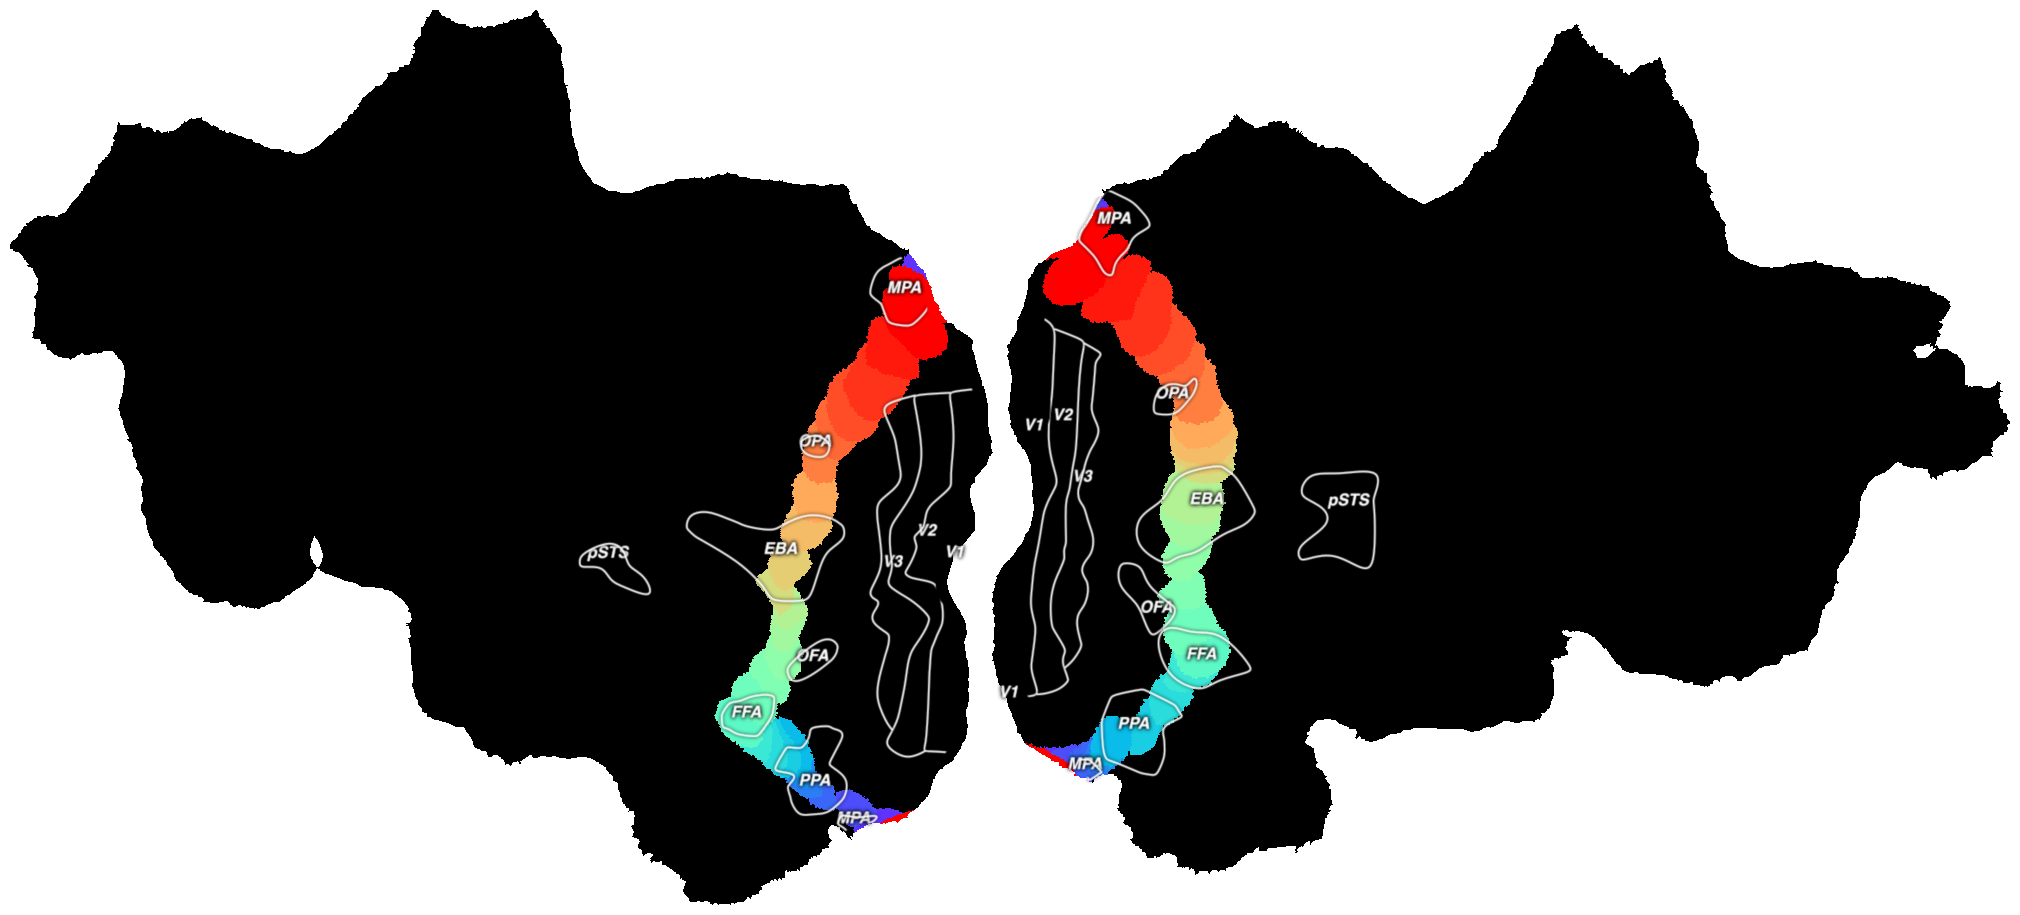

Subject 2: 31 spheres, 299271 vertices
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag


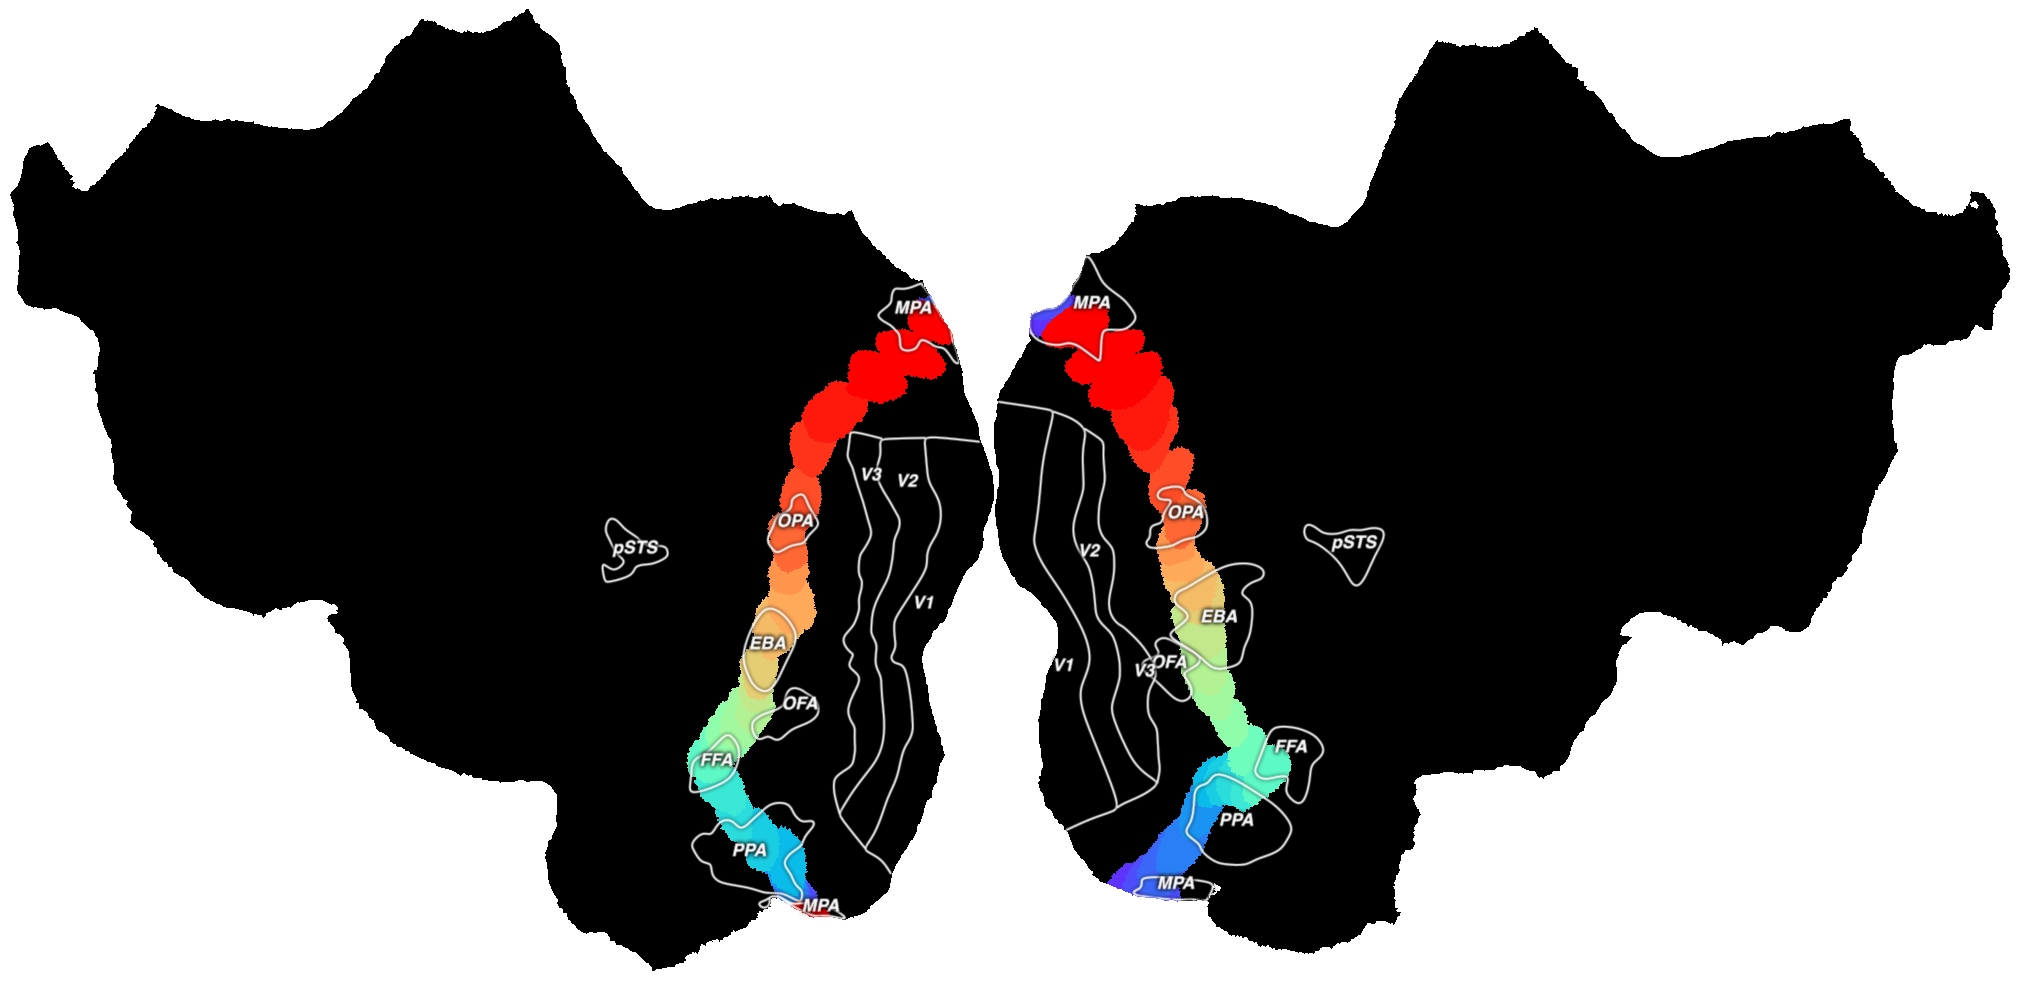

Subject 3: 31 spheres, 263299 vertices
Fontconfig warning: ignoring UTF-8: not a valid region tag
Fontconfig warning: ignoring UTF-8: not a valid region tag


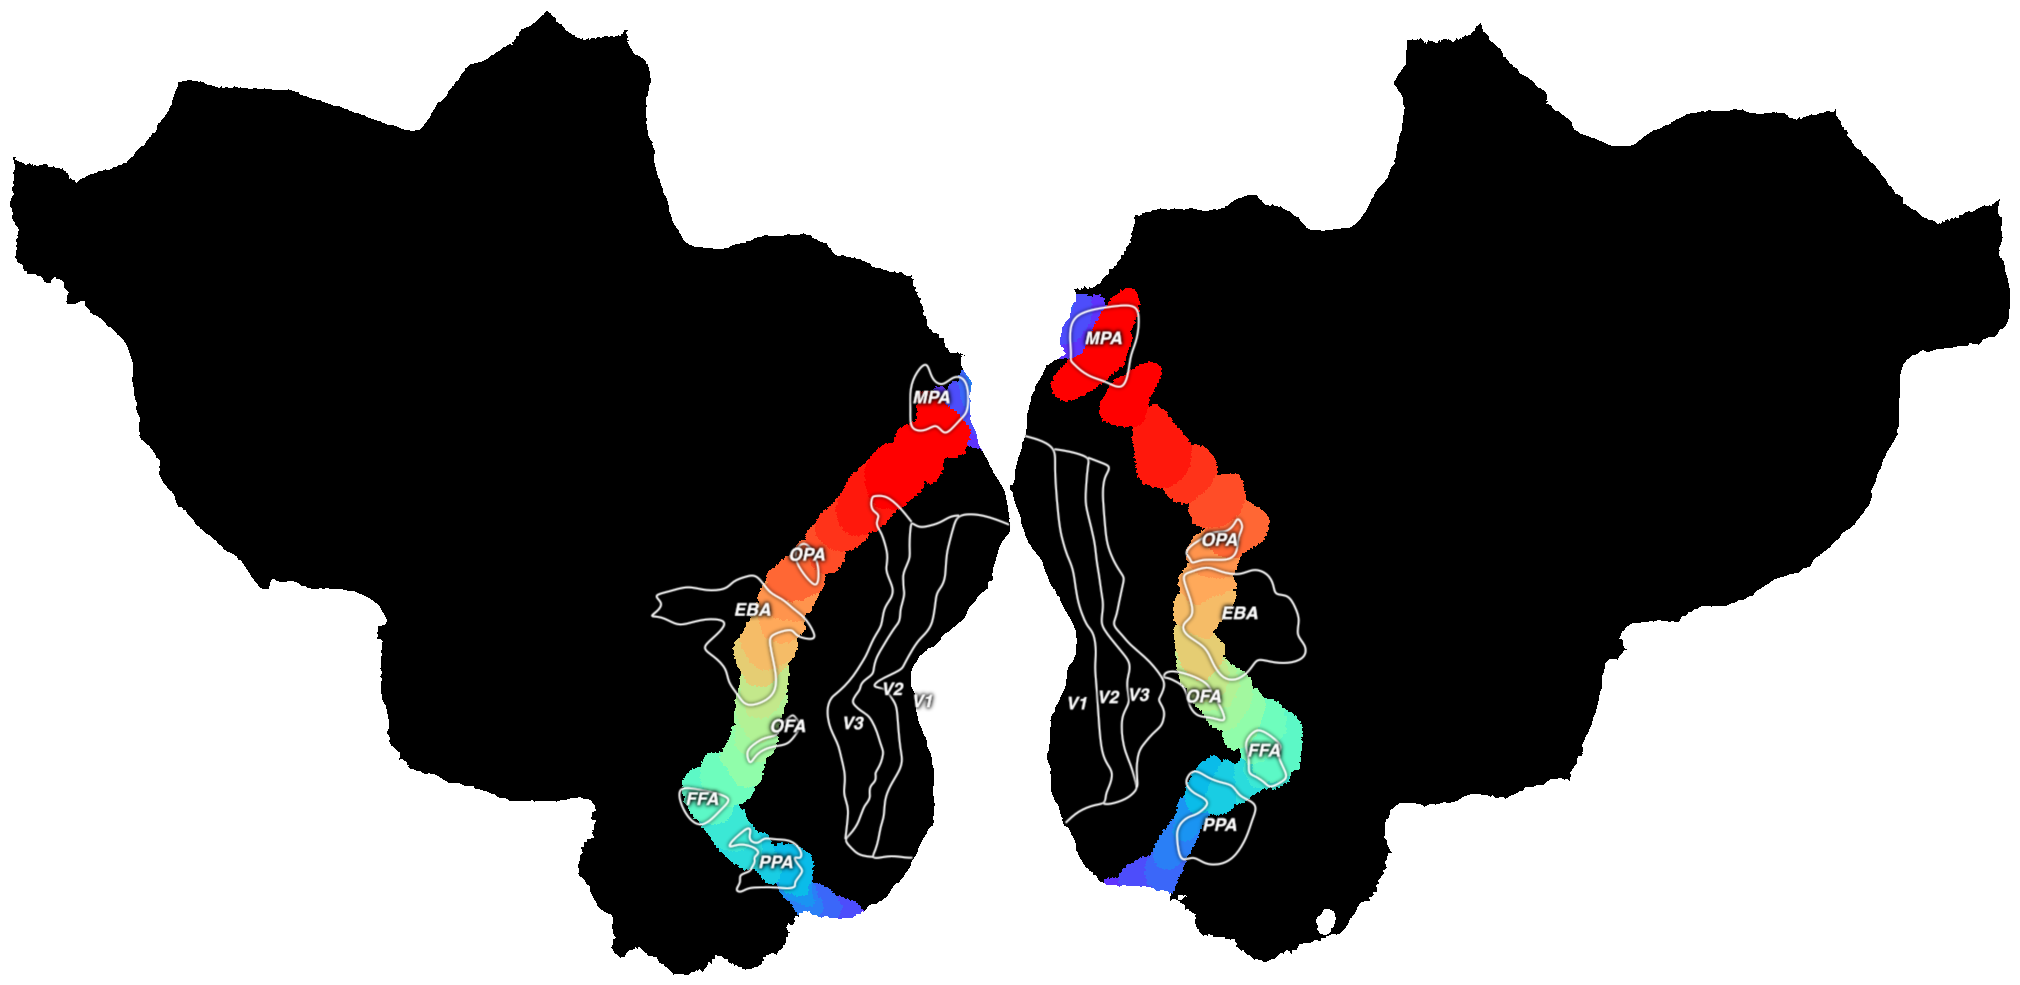

In [5]:
resdir = pjoin(rootdir, "results/vector-of-roi/")

subjects = [1, 2, 3]
xfmname = "align_auto"

roi_select = ["V1", "V2", "V3", "FFA", "OFA", "PPA", "EBA", "pSTS", "MPA", "OPA"]

for subject in subjects:
    filename = pjoin(resdir, f"sub0{subject}_surf_spheres.pkl")
    with open(filename, "rb") as f:
        spheres = pickle.load(f)

    print(f"Subject {subject}: {spheres.shape[0]} spheres, {spheres.shape[1]} vertices")

    # combine all spheres into one map, assigning each sphere its own label
    test_map = np.zeros(spheres.shape[1])

    for i, sphere in enumerate(spheres):
        test_map[sphere > 0] = i + 1

    # create colormap
    num_colors = spheres.shape[0]
    colormap = create_rainbow_colormap(num_colors)

    # create pycortex vertex map
    test_vert = cortex.Vertex(test_map, f"S{subject}", cmap=colormap)

    # convert to RGB so sphere colors remain discrete
    vertex_rgb = cortex.VertexRGB(
        test_vert.raw.red.data,
        test_vert.raw.green.data,
        test_vert.raw.blue.data,
        subject=f"S{subject}",
        #xfmname=xfmname
    )

    # plot
    fig = plt.figure(figsize=(20, 10))

    cortex.quickflat.make_figure(
        vertex_rgb,
        with_rois=True,
        roi_list=roi_select,
        with_sulci=True,
        with_colorbar=False,
        fig=fig
    )

    fig.savefig(pjoin(resdir, f"sub-0{subject}_vector_of_roi.png"), dpi=300, bbox_inches="tight")
    plt.show()